# Notebook 01 — GARCH & GJR-GARCH by Maximum Likelihood
**Goal:** Show that volatility clustering in S&P 500 (`^GSPC`) returns requires a time-varying variance model, fit GARCH(1,1) and GJR-GARCH(1,1) with Normal and Student-$t$ innovations from scratch via Maximum Likelihood, verify that standardized residuals remove the clustering, and prove estimator accuracy across 300 Monte Carlo simulations.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf
from arch import arch_model

from volrisk.universe import INDEX
from volrisk.data_loader import load_prices, log_returns_pct
from volrisk.garch import simulate_garch11, fit_garch, garch_variance

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

prices = load_prices()
r = log_returns_pct(prices[INDEX])
print(f"Loaded {len(r)} daily S&P 500 returns ({r.index[0].date()} to {r.index[-1].date()})")

Loaded 6537 daily S&P 500 returns (2000-01-04 to 2025-12-30)


### 1. Pre-Fit ARCH-Effect Diagnostics
Before fitting GARCH, we test raw returns $r_t$ and squared returns $r_t^2$ using the Ljung–Box test and Engle's ARCH-LM test. While raw returns show weak autocorrelation, squared returns $r_t^2$ exhibit overwhelming autocorrelation ($p < 10^{-16}$), confirming strong volatility clustering.

=== Ljung-Box on Raw Returns (r_t) ===
       lb_stat     lb_pvalue
10   97.070105  2.099054e-16
20  161.206901  4.390022e-24

=== Ljung-Box on Squared Returns (r_t^2) — The ARCH Effect ===
        lb_stat  lb_pvalue
10  5968.379218        0.0
20  8407.941132        0.0

Engle's ARCH-LM Test (10 lags): LM = 1749.98, p-value = 0.000e+00


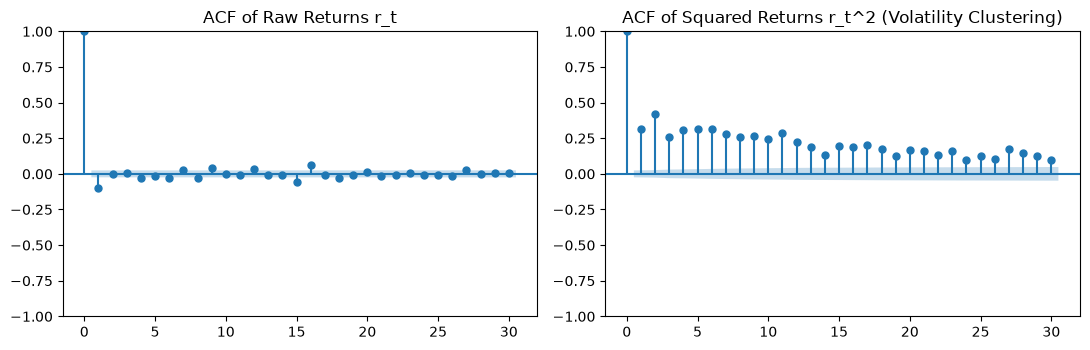

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

print("=== Ljung-Box on Raw Returns (r_t) ===")
print(acorr_ljungbox(r, lags=[10, 20], return_df=True))

print("\n=== Ljung-Box on Squared Returns (r_t^2) — The ARCH Effect ===")
print(acorr_ljungbox(r ** 2, lags=[10, 20], return_df=True))

lm_stat, lm_pval, f_stat, f_pval = het_arch(r - r.mean(), nlags=10)
print(f"\nEngle's ARCH-LM Test (10 lags): LM = {lm_stat:.2f}, p-value = {lm_pval:.3e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
plot_acf(r, lags=30, ax=ax[0], title="ACF of Raw Returns r_t")
plot_acf(r ** 2, lags=30, ax=ax[1], title="ACF of Squared Returns r_t^2 (Volatility Clustering)")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_acf_arch_effect.png", dpi=150)
plt.show()

### 2. Custom MLE Fits (GARCH-N, GARCH-$t$, GJR-$t$) & Cross-Check with `arch`
We fit GARCH(1,1)-Normal, GARCH(1,1)-Student-$t$, and GJR-GARCH(1,1)-Student-$t$ using our custom log-likelihood and compare our GARCH(1,1)-Normal estimates against the `arch` library. Small differences in the third decimal place arise solely because `arch` initializes $\sigma_0^2$ with an exponentially weighted backcast whereas we use the sample variance.

In [3]:
fit_gn = fit_garch(r, model="garch", dist="normal")
fit_gt = fit_garch(r, model="garch", dist="t")
fit_gjrt = fit_garch(r, model="gjr", dist="t")

am_ref = arch_model(r, mean="Constant", vol="GARCH", p=1, q=1, dist="normal").fit(disp="off")
print("=== Cross-Check vs arch Library (GARCH(1,1)-Normal) ===")
print("Custom MLE params [mu, omega, alpha, beta]:", np.round(fit_gn["params"], 4), "| LogLik:", round(fit_gn["loglik"], 2))
print("arch lib   params [mu, omega, alpha, beta]:", np.round(am_ref.params.to_numpy(), 4), "| LogLik:", round(am_ref.loglikelihood, 2))

def _ic(fit_dict, n_obs):
    k = len(fit_dict["params"])
    ll = fit_dict["loglik"]
    return round(ll, 2), round(2 * k - 2 * ll, 2), round(k * np.log(n_obs) - 2 * ll, 2)

models_tbl = pd.DataFrame([
    {"Model": "GARCH(1,1)-Normal", "Params": np.round(fit_gn["params"], 4).tolist(),
     **dict(zip(["LogLik", "AIC", "BIC"], _ic(fit_gn, len(r))))},
    {"Model": "GARCH(1,1)-Student-t", "Params": np.round(fit_gt["params"], 4).tolist(),
     **dict(zip(["LogLik", "AIC", "BIC"], _ic(fit_gt, len(r))))},
    {"Model": "GJR-GARCH(1,1)-t", "Params": np.round(fit_gjrt["params"], 4).tolist(),
     **dict(zip(["LogLik", "AIC", "BIC"], _ic(fit_gjrt, len(r))))},
])
print("\n=== Model Comparison (AIC / BIC) ===")
print(models_tbl.to_string(index=False))

persistence = fit_gn["params"][2] + fit_gn["params"][3]
half_life = np.log(0.5) / np.log(persistence)
print(f"\nGARCH(1,1) Persistence (alpha + beta) = {persistence:.4f} | Shock Half-Life = {half_life:.1f} trading days")
print(f"GJR Leverage parameter gamma = {fit_gjrt['params'][4]:.4f} (> 0 confirms bad news raises vol more than good news)")
print(f"Student-t degrees of freedom nu = {fit_gjrt['params'][5]:.2f} (confirms heavy-tailed innovations)")

=== Cross-Check vs arch Library (GARCH(1,1)-Normal) ===
Custom MLE params [mu, omega, alpha, beta]: [0.0624 0.0248 0.1221 0.8595] | LogLik: -8997.72
arch lib   params [mu, omega, alpha, beta]: [0.0625 0.0248 0.1222 0.8593] | LogLik: -8995.9

=== Model Comparison (AIC / BIC) ===
               Model                                     Params   LogLik      AIC      BIC
   GARCH(1,1)-Normal           [0.0624, 0.0248, 0.1221, 0.8595] -8997.72 18003.44 18030.58
GARCH(1,1)-Student-t   [0.0793, 0.0153, 0.1239, 0.8717, 6.2042] -8844.32 17698.63 17732.56
    GJR-GARCH(1,1)-t [0.0501, 0.0185, 0.0, 0.88, 0.2081, 6.871] -8730.19 17472.39 17513.10

GARCH(1,1) Persistence (alpha + beta) = 0.9816 | Shock Half-Life = 37.2 trading days
GJR Leverage parameter gamma = 0.2081 (> 0 confirms bad news raises vol more than good news)
Student-t degrees of freedom nu = 6.87 (confirms heavy-tailed innovations)


### 3. Standardized Residual Diagnostics & Conditional Volatility Path
After fitting GARCH, we standardize the residuals: $z_t = (r_t - \hat{\mu}) / \hat{\sigma}_t$. The Ljung–Box test on $z_t^2$ now yields high $p$-values ($> 0.05$), confirming that our GARCH variance recursion successfully absorbed the volatility clustering.

Standardized residuals z_t: mean = -0.0464, std = 0.9997

=== Ljung-Box on Standardized Squared Residuals (z_t^2) ===
      lb_stat  lb_pvalue
10  15.548051   0.113322
20  20.226806   0.443825


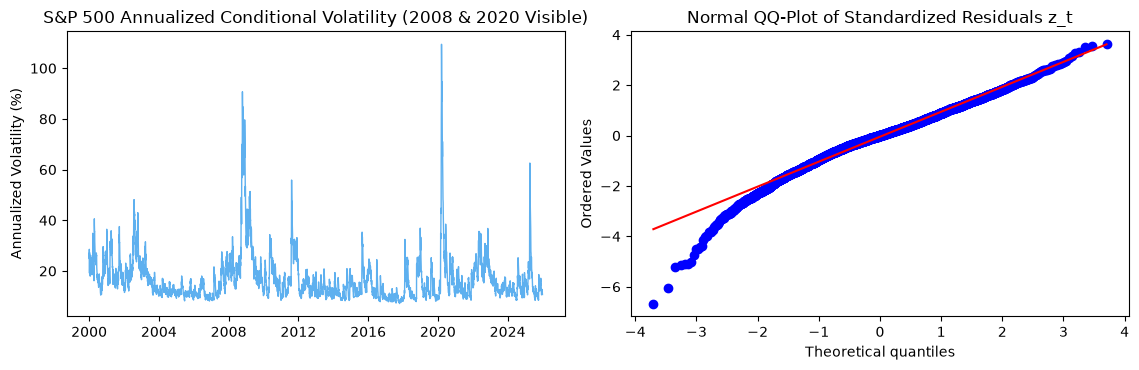

In [4]:
mu, omega, alpha, beta = fit_gn["params"]
s2_hat = garch_variance(omega, alpha, beta, r.to_numpy() - mu)
z_std = (r.to_numpy() - mu) / np.sqrt(s2_hat)

print(f"Standardized residuals z_t: mean = {z_std.mean():.4f}, std = {z_std.std(ddof=1):.4f}")
print("\n=== Ljung-Box on Standardized Squared Residuals (z_t^2) ===")
print(acorr_ljungbox(z_std ** 2, lags=[10, 20], return_df=True))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax[0].plot(r.index, np.sqrt(252 * s2_hat), color="#5eb0ef", lw=1)
ax[0].set_title("S&P 500 Annualized Conditional Volatility (2008 & 2020 Visible)")
ax[0].set_ylabel("Annualized Volatility (%)")

stats.probplot(z_std, dist="norm", plot=ax[1])
ax[1].set_title("Normal QQ-Plot of Standardized Residuals z_t")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_conditional_vol.png", dpi=150)
plt.show()

### 4. Parameter-Recovery Experiment (Killer Figure: 300 Simulations, $T = 2,000$)
To prove our Maximum Likelihood estimator and numerical Hessian standard errors work properly, we simulate 300 independent GARCH(1,1) series with known parameters $(\mu=0.05, \omega=0.05, \alpha=0.08, \beta=0.90)$, fit our MLE to each, and inspect the bias, spread, and 95% confidence interval coverage.

=== Parameter Recovery across 300 Simulated Series (T = 2,000) ===
Param  True  Mean_Est    Bias     SD   RMSE  SE_95%_Coverage_%
   mu  0.05    0.0534  0.0034 0.0292 0.0293               97.3
omega  0.05    0.0583  0.0083 0.0225 0.0240               95.3
alpha  0.08    0.0805  0.0005 0.0139 0.0139               92.7
 beta  0.90    0.8956 -0.0044 0.0186 0.0191               94.3


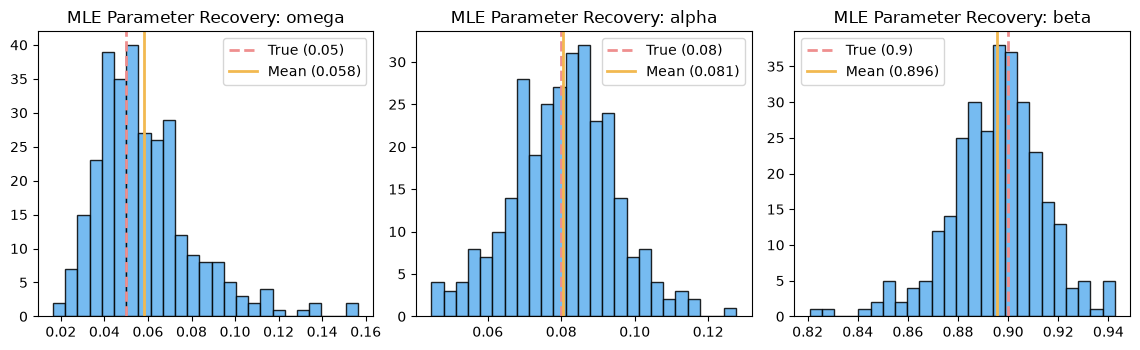

In [5]:
truth = np.array([0.05, 0.05, 0.08, 0.90])  # [mu, omega, alpha, beta]
n_sims, T = 300, 2000
ests = np.empty((n_sims, 4))
covered = np.zeros((n_sims, 4), dtype=bool)

for s in range(n_sims):
    sim_r = simulate_garch11(T, *truth, seed=100 + s)
    res = fit_garch(sim_r, model="garch", dist="normal", compute_se=True)
    ests[s] = res["params"]
    covered[s] = np.abs(res["params"] - truth) <= 1.96 * res["se"]

rec_df = pd.DataFrame({
    "Param": ["mu", "omega", "alpha", "beta"],
    "True": truth,
    "Mean_Est": ests.mean(axis=0).round(4),
    "Bias": (ests.mean(axis=0) - truth).round(4),
    "SD": ests.std(axis=0, ddof=1).round(4),
    "RMSE": np.sqrt(((ests - truth) ** 2).mean(axis=0)).round(4),
    "SE_95%_Coverage_%": (100.0 * covered.mean(axis=0)).round(1),
})
print("=== Parameter Recovery across 300 Simulated Series (T = 2,000) ===")
print(rec_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6))
for i, (idx, name) in enumerate([(1, "omega"), (2, "alpha"), (3, "beta")]):
    axes[i].hist(ests[:, idx], bins=25, color="#5eb0ef", edgecolor="black", alpha=0.85)
    axes[i].axvline(truth[idx], color="#ef8f8f", ls="--", lw=2, label=f"True ({truth[idx]})")
    axes[i].axvline(ests[:, idx].mean(), color="#f2b950", lw=2, label=f"Mean ({ests[:, idx].mean():.3f})")
    axes[i].set_title(f"MLE Parameter Recovery: {name}")
    axes[i].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "01_parameter_recovery.png", dpi=150)
plt.show()